# Etapa 2 — Experimentos de pré-processamento

**Disciplina:** Inteligência Artificial — Profa. Cristiane Neri Nobre
**Trabalho em competição:** Detecção de Intrusão em Redes (NSL-KDD, base atualizada)
**Equipe:** _preencher_
**Etapa 2 — entrega 07/11/2026**

**Objetivo.** Implementar e comparar, de forma explícita, as técnicas de pré-processamento
exigidas na Seção 4 do enunciado: (1) tratamento de dados redundantes/inconsistentes,
(2) ao menos 2 técnicas de balanceamento, (3) codificação simbólico-numérica de `service`,
(4) normalização/transformação numérica e (5) redução de dimensionalidade. Somamos dois
problemas que a Etapa 1 encontrou na base: valores impossíveis e valores ausentes.

**Resumo dos resultados** (F1-macro de CV agrupada 5-fold no treino; regra: só troca a opção
mais simples por outra se o ganho passar de 1 desvio-padrão)

- **Redundância/inconsistência:** só o boosting ganha com a limpeza de rótulos. No HGB,
  `majority_label` sobe de 0,9754 para 0,9820. RF (bagging) e MLP não mudam além do ruído, e
  reclassificar os conflitos com um modelo (`relabel_model`) não supera a remoção simples.
- **Valores impossíveis:** tratá-los como ausentes (`nan`) é ao menos tão bom quanto saturar ou
  manter, nas duas famílias testadas.
- **Ausentes:** NaN nativo no HGB e mediana no RF e no MLP. O indicador de ausência não ajudou,
  apesar do padrão MNAR de `dst_host_serror_rate`.
- **Codificação de `service`:** one-hot vence ou empata com frequência, target, ordinal e
  one-hot com raras agrupadas. Nenhuma alternativa passa da regra.
- **Balanceamento:** nenhuma das 7 técnicas testadas supera `none`. RUS e `class_weight` pioram.
  Com o limiar de decisão ajustado por OOF, o desbalanceamento 16:1 já é tratado na decisão.
- **Transformação numérica:** no MLP, `log1p` + padronização é a melhor (0,9641); sem o `log1p`
  cai para 0,9551.
- **Redução:** seleção por árvores (`tree_select`) é a única que não perde (RF: 0,9813) e mantém
  os atributos originais. O PCA perde nas duas famílias, mesmo com dados padronizados.
- **Robustez (CV 3×5):** o ganho da limpeza de rótulos no HGB se confirma (0,9741 → 0,9824). O
  ganho do `tree_select` no RF não se confirma (+0,0008): ele fica por desempenho equivalente com
  metade das colunas e atributos originais, não por ser melhor.

**Índice**
0. Configuração e política de dados
1. Protocolo experimental
2. Dados redundantes e inconsistentes (requisito 1)
3. Valores impossíveis
4. Valores ausentes
5. Codificação simbólico-numérica de `service` (requisito 3)
6. Balanceamento de classes (requisito 2)
7. Normalização e transformação numérica (requisito 4)
8. Redução de dimensionalidade (requisito 5)
9. Robustez das escolhas (CV repetida)
10. Tabela comparativa consolidada e configurações escolhidas
11. Conclusões e plano para a Etapa 3

## 0. Configuração e política de dados

Bibliotecas, semente global (`config.RANDOM_STATE = 42`) e o registro de experimentos.
`ExperimentLog` grava cada configuração em `results/experiments.csv` com uma chave (hash) da
configuração e da versão da base. Reexecutar o notebook lê do registro o que já foi calculado
e só roda a CV do que falta. Apagar o CSV refaz todos os experimentos do zero, com o mesmo
resultado, porque todas as sementes são fixas.

In [1]:
import json
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, sklearn, imblearn
from IPython.display import display
from nslkdd import ExperimentLog, config, load_train
from nslkdd.data import conflict_mask, evaluation_mask
from nslkdd.models import make_model
from nslkdd.preprocessing import DomainCleaner, signed_log1p
from nslkdd.search import AXES, FAMILIES, FOLD_JOBS, coordinate_search, describe, threads

X, y, groups = load_train()
log = ExperimentLog()
np.random.seed(config.RANDOM_STATE)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
config.FIGURES.mkdir(parents=True, exist_ok=True)

# Uma cor fixa por família de algoritmo, em todos os gráficos.
FAMILY_COLOR = {"HGB_native": "#2a78d6", "RF": "#eb6834", "MLP": "#1baf7a"}
FAMILY_NAME = {"HGB_native": "HGB (boosting)", "RF": "Random Forest", "MLP": "MLP"}

print({m.__name__: m.__version__ for m in (np, pd, sklearn, imblearn)})
print("RANDOM_STATE =", config.RANDOM_STATE, "| versão da base:", log.data_version)
print("X:", X.shape, "| classes:", y.value_counts().to_dict())

{'numpy': '2.5.4', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'imblearn': '0.14.2'}
RANDOM_STATE = 42 | versão da base: db8fb3ac
X: (69833, 41) | classes: {'normal': 65754, 'anomaly': 4079}


**Política de dados.**
- Só `treino.csv` é usado aqui. O teste (`teste_sem_rotulo.csv`) só entra no notebook 04,
  uma única vez, depois de congelada a configuração final. `data/raw/` (NSL-KDD original) não
  é usada: contém as linhas do teste com os rótulos.
- `X` tem só os 41 atributos de rede (`config.FEATURES`). As colunas de vazamento
  (`score_ids_legado`, `tipo_alerta_soc`, `tempo_resposta_analista_min`) e as 5 cópias
  derivadas ficaram de fora já na carga, pelos motivos mostrados na Etapa 1.
- Toda técnica que aprende algo dos dados (remoção de redundâncias, imputação, codificação,
  escala, redução, balanceamento) é um passo do `Pipeline` do imbalanced-learn montado por
  `build_pipeline`. A validação cruzada recebe o pipeline inteiro, então cada passo é ajustado
  só nos folds de treino. As contagens descritivas deste notebook (quantas linhas cada
  estratégia removeria, quantos valores são impossíveis) não alimentam nenhum modelo.

## 1. Protocolo experimental

**Validação.** `StratifiedGroupKFold` com 5 folds, agrupado por duplicata: as 13.067 cópias da
Etapa 1 nunca ficam uma no treino e outra na validação, o que inflaria a nota.

**Métrica.** F1-macro, a métrica oficial. Cada fold é pontuado só nas linhas que medem
generalização: uma por grupo de cópias, sem rótulo contraditório. Nos 1.702 grupos com a mesma
linha rotulada com as duas classes, nenhum modelo acerta mais que metade, e esse ruído esconde
as diferenças entre técnicas. O F1-macro sobre todas as linhas (`f1_macro_bruto`) aparece como
contraste, mas não decide nada: fica preso perto de 0,88 pelos conflitos.

**Limiar de decisão.** O F1-macro depende do ponto de corte da probabilidade. Em cada fold, o
limiar é escolhido nas previsões out-of-fold dos *outros* folds, então o fold pontuado nunca
ajuda a escolher o próprio limiar.

**Busca por coordenadas.** Testar todas as combinações seria inviável (5 × 3 × 5 × 5 × 8 × 5 × 5
opções). Variamos **um eixo por vez**, com os demais fixos na melhor escolha até então, na ordem
do fluxo de dados: redundância → domínio → imputação → codificação → escala → balanceamento →
redução.

**Regra de decisão, declarada antes de ver os resultados.** A primeira opção de cada eixo é a
mais simples. Outra só a substitui se superar o F1-macro dela em **mais de 1 desvio-padrão**
entre folds. Diferença menor que isso é variação de amostragem, e a simplicidade vence.

**Três famílias de algoritmos.** A melhor técnica de pré-processamento depende do modelo:
- **HGB** (`HistGradientBoostingClassifier`): boosting, aceita NaN e categorias nativamente.
- **Random Forest**: bagging de árvores, exige imputação e codificação numérica.
- **MLP** (rede neural): sensível a escala e a distâncias. Sem ela, a comparação de
  normalização seria vazia, porque árvores são invariantes a transformações monotônicas.

Pontos de partida (a configuração mais simples que cada algoritmo aceita):

In [2]:
display(pd.DataFrame(FAMILIES).T.fillna("—"))
print("Eixos por família:", {f: [a for a, _ in AXES[f]] for f in AXES})

,redundancy,domain,imputation,scaling,log_transform,service_encoding,categorical_encoding
HGB_native,none,nan,none,none,False,ordinal,ordinal
RF,none,nan,median,none,False,onehot,onehot
MLP,none,nan,median,standard,True,onehot,—


Eixos por família: {'HGB_native': ['redundancia', 'dominio', 'imputacao', 'balanceamento'], 'RF': ['redundancia', 'imputacao', 'codificacao', 'balanceamento', 'reducao'], 'MLP': ['redundancia', 'dominio', 'imputacao', 'codificacao', 'escala', 'balanceamento', 'reducao']}


A busca completa abaixo roda (ou lê do registro) as 71 configurações. Cada CV de 5 folds leva de
10 a 80 segundos; tudo junto, cerca de 40 minutos na primeira execução. O mesmo código está em
`nslkdd.search`, usado também por `tools/rodar_experimentos.py`.

In [3]:
best, results = coordinate_search(log, X, y, groups, verbose=False)
results.to_csv(config.RESULTS / "etapa2_resultados_por_eixo.csv", index=False)
print(f"{len(results)} configurações avaliadas em {results['segundos'].sum() / 60:.0f} min de CV.")

71 configurações avaliadas em 40 min de CV.


Funções de apoio: a tabela de cada eixo e um gráfico de pontos com barra de ±1 desvio-padrão,
uma coluna por família. O ponto cheio marca a opção escolhida pela regra; a linha tracejada
marca a opção de referência (a mais simples), e a faixa cinza, ±1 dp em torno dela, mostra a
margem que uma alternativa precisa vencer.

In [4]:
COLS = ["familia", "opcao", "f1_macro", "dp", "ganho_vs_ref", "f1_macro_bruto",
        "precision_anomaly", "recall_anomaly", "limiar", "escolhida"]


def axis_table(axis):
    return results.loc[results["eixo"] == axis, COLS].reset_index(drop=True)


def plot_axis(axis, title, xlim=None):
    data = results[results["eixo"] == axis]
    families = [f for f in FAMILY_COLOR if f in set(data["familia"])]
    height = 0.42 * data.groupby("familia").size().max() + 1.3
    fig, axes = plt.subplots(1, len(families), figsize=(4.6 * len(families), height),
                             sharex=True, squeeze=False)
    for ax, family in zip(axes[0], families):
        d = data[data["familia"] == family].reset_index(drop=True)
        pos = np.arange(len(d))[::-1]
        ref, ref_sd = d.loc[0, "f1_macro"], d.loc[0, "dp"]
        ax.axvspan(ref - ref_sd, ref + ref_sd, color="#e6e5e0", zorder=0)
        ax.axvline(ref, color="#8a8980", lw=1, ls="--", zorder=1)
        color = FAMILY_COLOR[family]
        ax.errorbar(d["f1_macro"], pos, xerr=d["dp"], fmt="none", ecolor=color, elinewidth=2,
                    capsize=0, zorder=2)
        for p, (_, row) in zip(pos, d.iterrows()):
            if xlim and row["f1_macro"] < xlim[0]:  # fora da escala: seta na borda + valor
                ax.annotate(f"< {row['f1_macro']:.3f} (fora da escala)".replace(".", ","), (xlim[0], p),
                            xytext=(4, 0), textcoords="offset points", va="center",
                            fontsize=9, color="#52514c")
                continue
            ax.plot(row["f1_macro"], p, "o", ms=8, zorder=3, mec=color, mew=2,
                    mfc=color if row["escolhida"] else "white")
        ax.set_yticks(pos, d["opcao"])
        ax.set_title(FAMILY_NAME[family], fontsize=11)
        ax.set_xlabel("F1-macro (CV agrupada, ±1 dp)")
        ax.grid(axis="y", visible=False)
        if xlim:
            ax.set_xlim(*xlim)
    fig.suptitle(title, fontsize=12, x=0.01, ha="left")
    fig.tight_layout()
    fig.savefig(config.FIGURES / f"pre_{axis}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Dados redundantes e inconsistentes (requisito 1)

A Etapa 1 mostrou dois problemas de instâncias:
- **Redundância:** 19% das linhas são cópias de outras (os 41 atributos idênticos). Cópias
  inflam o peso de padrões repetidos no ajuste.
- **Inconsistência:** o material da disciplina define instâncias inconsistentes como "duas
  instâncias iguais com classificações diferentes". Aqui há 1.702 grupos assim, ruído de rótulo
  injetado na base.

Comparamos cinco estratégias, todas aplicadas **dentro do pipeline**, só no fold de treino:

| Estratégia | O que faz |
|---|---|
| `none` | mantém tudo (referência) |
| `drop_duplicates` | remove cópias com o mesmo rótulo; conflitos ficam |
| `drop_inconsistent` | uma linha por grupo e descarta os grupos com conflito |
| `majority_label` | uma linha por grupo com o rótulo da maioria estrita; empates saem |
| `relabel_model` | conflitos recebem o rótulo de um HGB treinado nas linhas limpas do fold; os incertos (probabilidade < 0,8) saem |

Quantas linhas cada estratégia deixaria, se aplicada ao treino inteiro (só descritivo; na CV,
cada fold de treino aplica a sua):

In [5]:
first = ~pd.Series(groups).duplicated().to_numpy()
conflict = conflict_mask(groups, y)
pair_dup = pd.DataFrame({"g": groups, "y": y.to_numpy()}).duplicated().to_numpy()
votes = pd.crosstab(groups, y)
strict = votes.max(axis=1) > votes.sum(axis=1) / 2  # maioria estrita no grupo
majority_ok = pd.Series(groups).map(strict).to_numpy()
n = len(y)
redundancy_counts = pd.DataFrame({
    "linhas mantidas": [n, (~pair_dup).sum(), (first & ~conflict).sum(), (first & majority_ok).sum()],
}, index=["none", "drop_duplicates", "drop_inconsistent", "majority_label"])
redundancy_counts["% do treino"] = (100 * redundancy_counts["linhas mantidas"] / n).round(1)
display(redundancy_counts)
print(f"Grupos com conflito: {pd.Series(groups[conflict]).nunique():,} ({conflict.sum():,} linhas); "
      f"desses, {(~strict[strict.index.isin(np.unique(groups[conflict]))]).sum():,} grupos empatados.")

,linhas mantidas,% do treino
none,69833,100.0
drop_duplicates,58468,83.7
drop_inconsistent,55064,78.9
majority_label,55390,79.3


Grupos com conflito: 1,702 (3,730 linhas); desses, 1,376 grupos empatados.


Resultado da CV nas três famílias:

,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,HGB_native,none,0.9754,0.0036,0.0000,0.8776,0.9641,0.9410,0.310,False
1,HGB_native,drop_duplicates,0.9750,0.0031,-0.0004,0.8767,0.9750,0.9294,0.356,False
2,HGB_native,drop_inconsistent,0.9808,0.0008,0.0054,0.8806,0.9786,0.9476,0.330,False
3,HGB_native,majority_label,0.9820,0.0015,0.0066,0.8816,0.9778,0.9531,0.284,True
4,HGB_native,relabel_model,0.9795,0.0020,0.0041,0.8799,0.9766,0.9448,0.292,False
5,RF,none,0.9791,0.0021,0.0000,0.8800,0.9703,0.9492,0.360,True
6,RF,drop_duplicates,0.9790,0.0028,-0.0001,0.8804,0.9677,0.9515,0.334,False
7,RF,drop_inconsistent,0.9776,0.0021,-0.0015,0.8789,0.9688,0.9453,0.344,False
8,RF,majority_label,0.9783,0.0036,-0.0008,0.8798,0.9655,0.9510,0.346,False
9,RF,relabel_model,0.9791,0.0020,0.0000,0.8799,0.9747,0.9454,0.370,False


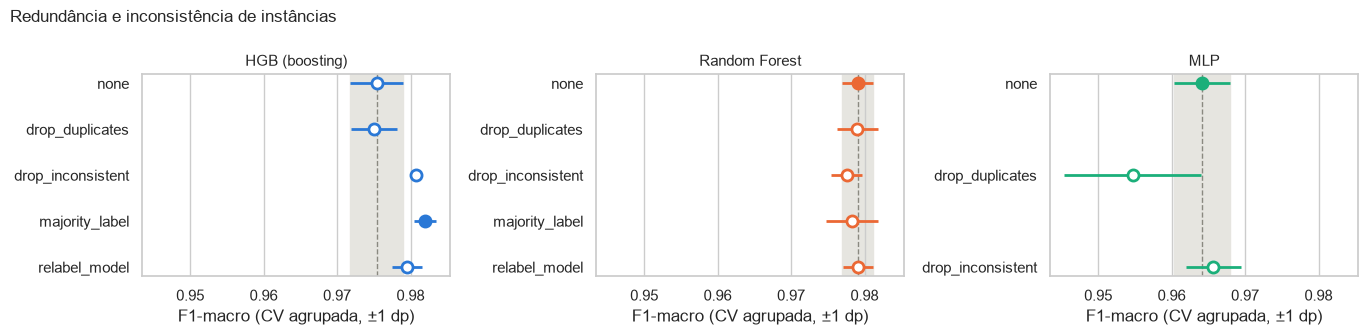

In [6]:
display(axis_table("redundancia"))
plot_axis("redundancia", "Redundância e inconsistência de instâncias")

**O que se conclui.**
- **HGB:** a limpeza de rótulos ajuda claramente. `majority_label` (0,9820 ± 0,0015) e
  `drop_inconsistent` (0,9808) superam `none` (0,9754 ± 0,0036) por mais de 1 dp. O boosting
  ajusta cada árvore aos erros das anteriores, então insiste em acertar exemplos com rótulo
  trocado e acaba memorizando o ruído. Removê-los antes do ajuste corrige isso. Escolha:
  `majority_label`, que aproveita a informação dos grupos com três ou mais cópias.
- **RF:** nenhuma estratégia passa da regra (todas entre 0,9776 e 0,9791). O bagging já é robusto
  a ruído de rótulo: cada árvore vê uma amostra diferente, e o voto dilui os exemplos trocados.
  Fica `none`.
- **MLP:** `drop_inconsistent` (0,9657) não supera `none` (0,9641 ± 0,0038) por 1 dp, e
  `drop_duplicates` piora. Fica `none`.
- **`relabel_model` não compensou** em nenhuma família: recuperar parte dos conflitos com um
  modelo não superou simplesmente removê-los. É um resultado negativo útil: a informação extra
  não paga o risco de propagar os erros do próprio modelo.
- `drop_duplicates` sozinho não muda nada nas árvores: o problema não são as cópias, são os
  rótulos contraditórios.

## 3. Valores impossíveis

A Etapa 1 encontrou valores fora da definição dos atributos: taxas maiores que 1, contagens
acima da janela do KDD (511 conexões, 255 hosts) e negativos em atributos não negativos. Eles
não têm relação com a classe e parecem erro de medição. Os limites vêm da definição dos
atributos, não de estatísticas da base, então o tratamento é por linha e não aprende nada.

| Estratégia | O que faz |
|---|---|
| `nan` | o valor vira ausente e segue para a imputação (referência) |
| `none` | mantém o valor como está |
| `clip` | satura no limite (taxa 3,2 → 1,0; negativo → 0) |

A referência é `nan` porque não há como recuperar o valor correto: 600 em uma taxa pode ser
6 × 100 ou 60 × 10. Saturar inventa um valor; tratar como ausente admite que ele se perdeu.

In [7]:
cleaned = DomainCleaner("nan").fit(X).transform(X)
impossible = (cleaned[config.NUMERIC].isna() & X[config.NUMERIC].notna()).sum()
impossible = impossible[impossible > 0].sort_values(ascending=False)
rows_hit = (cleaned[config.NUMERIC].isna() & X[config.NUMERIC].notna()).any(axis=1)
print(f"Linhas com algum valor impossível: {rows_hit.sum():,} ({rows_hit.mean():.1%})")
print(f"Taxa de anomaly nessas linhas: {(y[rows_hit] == 'anomaly').mean():.1%} "
      f"(base: {(y == 'anomaly').mean():.1%})")
display(impossible.head(10).rename("valores impossíveis").to_frame())

Linhas com algum valor impossível: 5,674 (8.1%)
Taxa de anomaly nessas linhas: 5.9% (base: 5.8%)


,valores impossíveis
dst_host_count,912
dst_host_srv_diff_host_rate,739
dst_host_srv_rerror_rate,714
rerror_rate,683
dst_host_same_srv_rate,670
dst_host_diff_srv_rate,623
srv_count,507
count,464
duration,382
src_bytes,189


,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,HGB_native,nan,0.9820,0.0015,0.0000,0.8816,0.9778,0.9531,0.284,True
1,HGB_native,none,0.9804,0.0015,-0.0016,0.8805,0.9773,0.9476,0.318,False
2,HGB_native,clip,0.9803,0.0016,-0.0017,0.8804,0.9792,0.9454,0.364,False
3,MLP,nan,0.9641,0.0038,0.0000,0.8696,0.9534,0.9102,0.428,True
4,MLP,none,0.9589,0.0049,-0.0052,0.8672,0.9371,0.9063,0.392,False
5,MLP,clip,0.9635,0.0040,-0.0006,0.8700,0.9494,0.9113,0.396,False


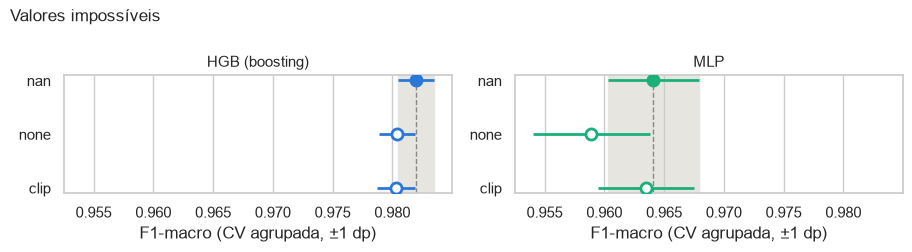

In [8]:
display(axis_table("dominio"))
plot_axis("dominio", "Valores impossíveis")

**O que se conclui.** `nan` é a melhor opção nas duas famílias testadas (HGB 0,9820; MLP 0,9641).
No HGB, `none` e `clip` perdem o mesmo (cerca de 0,0016). No MLP, `clip` empata e manter o valor
(`none`) perde 0,005: um valor como 600 em uma taxa vira, depois da padronização, um ponto extremo
que distorce os pesos da rede. O RF não foi testado neste eixo: a escolha das árvores já estava coberta pelo HGB, e
a regra manteria a referência. Fica `nan` em todas as famílias.

## 4. Valores ausentes

94% das linhas têm algum ausente (até 40% em `src_bytes`). Descartar linhas é inviável, e o
teste também tem ausentes, então o modelo precisa saber lidar com eles. Comparamos:

| Estratégia | O que faz |
|---|---|
| `none` | NaN nativo: o HGB aprende para que lado da divisão vai o ausente (só árvores) |
| `mean`, `median` | substitui pela média ou mediana do fold de treino |
| `median_indicator` | mediana + uma coluna binária "estava ausente" por atributo |
| `iterative` | estima cada atributo a partir dos outros (MICE, `IterativeImputer`) |

Atributos categóricos ausentes viram a categoria `ausente` em todas as estratégias.

A Etapa 1 mostrou que `dst_host_serror_rate` é MNAR (valores altos somem mais, e valor alto
indica ataque). A mediana apaga esse sinal; o NaN nativo e o indicador o preservam.

In [9]:
missing = X.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]
print(f"Atributos com ausentes: {len(missing)} | linhas com algum ausente: {X.isna().any(axis=1).mean():.1%}")
col = "dst_host_serror_rate"
is_na = X[col].isna()
print(f"{col}: taxa de anomaly com ausente {(y[is_na] == 'anomaly').mean():.1%} "
      f"× sem ausente {(y[~is_na] == 'anomaly').mean():.1%}")
display((100 * missing.head(8)).round(1).rename("% ausente").to_frame())

Atributos com ausentes: 24 | linhas com algum ausente: 93.8%
dst_host_serror_rate: taxa de anomaly com ausente 8.5% × sem ausente 4.6%


,% ausente
src_bytes,40.0
dst_host_srv_count,39.9
dst_host_serror_rate,30.6
dst_host_same_src_port_rate,28.0
serror_rate,6.8
service,6.3
logged_in,6.1
srv_diff_host_rate,6.1


,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,HGB_native,none,0.9820,0.0015,0.0000,0.8816,0.9778,0.9531,0.284,True
1,HGB_native,median,0.9811,0.0017,-0.0009,0.8816,0.9696,0.9576,0.186,False
2,HGB_native,median_indicator,0.9814,0.0012,-0.0006,0.8816,0.9722,0.9559,0.244,False
3,RF,median,0.9791,0.0021,0.0000,0.8800,0.9703,0.9492,0.360,True
4,RF,none,0.9801,0.0027,0.0010,0.8805,0.9750,0.9487,0.340,False
5,RF,median_indicator,0.9780,0.0036,-0.0011,0.8803,0.9622,0.9532,0.308,False
6,RF,mean,0.9783,0.0026,-0.0008,0.8800,0.9679,0.9487,0.326,False
7,MLP,median,0.9641,0.0038,0.0000,0.8696,0.9534,0.9102,0.428,True
8,MLP,mean,0.9608,0.0047,-0.0033,0.8679,0.9517,0.8997,0.420,False
9,MLP,median_indicator,0.9492,0.0045,-0.0149,0.8606,0.9286,0.8773,0.384,False


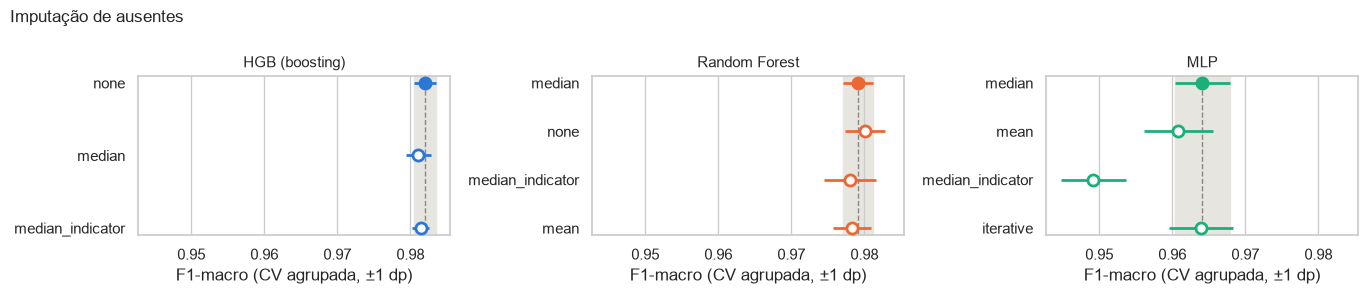

In [10]:
display(axis_table("imputacao"))
plot_axis("imputacao", "Imputação de ausentes")

**O que se conclui.**
- **HGB:** NaN nativo (0,9820) fica à frente da mediana (0,9811) e do indicador (0,9814).
  Nenhuma imputação supera a referência, e o NaN nativo é o mais simples: o modelo aprende
  sozinho o que o ausente significa em cada atributo.
- **RF:** NaN nativo (0,9801) e mediana (0,9791) empatam dentro de 1 dp. Fica a mediana.
- **MLP:** mediana (0,9641) e iterativa (0,9639) empatam; média perde pouco e o indicador perde
  0,015. O indicador dobra o número de colunas numéricas com sinais binários fracos, e a rede
  ajusta ruído com eles.
- O indicador não melhorou em nenhuma família, apesar do MNAR em `dst_host_serror_rate`. O sinal
  do ausente nesse atributo é pequeno perto do que os outros 40 atributos já informam. Relatamos
  o resultado assim mesmo, porque ele contraria a expectativa da Etapa 1.

## 5. Codificação simbólico-numérica de `service` (requisito 3)

`protocol_type` (3 valores) e `flag` (11) têm poucas categorias e usam one-hot (ou a codificação
nativa do HGB). O desafio é `service`: 67 categorias após padronizar a grafia
(68 contando `ausente`), com cauda longa.

In [11]:
svc = X["service"].fillna("ausente")
share = svc.value_counts(normalize=True)
rate = (y == "anomaly").groupby(svc).mean()
print(f"Categorias de service: {svc.nunique()} | as 5 maiores cobrem {share.head(5).sum():.1%} das linhas")
print(f"Categorias com < 0,1% das linhas (agrupadas por onehot_rare): {(share < 0.001).sum()}")
print(f"Taxa de anomaly por categoria: de {rate.min():.0%} a {rate.max():.0%}")
display(pd.DataFrame({"% linhas": (100 * share.head(8)).round(1),
                      "% anomaly": (100 * rate[share.head(8).index]).round(1)}))

Categorias de service: 68 | as 5 maiores cobrem 84.0% das linhas
Categorias com < 0,1% das linhas (agrupadas por onehot_rare): 50
Taxa de anomaly por categoria: de 0% a 100%


,% linhas,% anomaly
service,,
http,51.9,1.7
domain_u,11.0,1.0
smtp,8.7,1.3
ausente,6.3,6.2
ftp_data,6.1,3.0
private,4.2,40.0
other,3.1,5.9
ftp,1.6,6.1


Alternativas comparadas e o que cada uma assume:

| Codificação | Colunas | Prós e contras |
|---|---|---|
| `onehot` | 67 | não impõe ordem (distância de Hamming constante entre categorias); muitas colunas esparsas |
| `onehot_rare` | ~19 | one-hot com as categorias de < 0,1% das linhas em uma coluna "rara" |
| `frequency` | 1 | pseudoatributo: fração de linhas da categoria; categorias diferentes com a mesma frequência colapsam |
| `target` | 1 | pseudoatributo: taxa de `anomaly` da categoria, com *cross-fitting* interno para não vazar o rótulo |
| `ordinal` | 1 | inteiro arbitrário; impõe uma ordem falsa, aceitável só para árvores |
| nativa (HGB) | 1 | o HGB divide as categorias em grupos sem supor ordem |

O material da disciplina alerta que a codificação 1-de-c não é boa opção quando há muitas
categorias (o exemplo dos "193 países") e sugere pseudoatributos. Por isso testamos `frequency`
e `target` contra o one-hot. O HGB usa a codificação nativa e não entra neste eixo.

,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,RF,onehot,0.9791,0.0021,0.0000,0.8800,0.9703,0.9492,0.360,True
1,RF,onehot_rare,0.9806,0.0017,0.0015,0.8807,0.9735,0.9520,0.358,False
2,RF,frequency,0.9792,0.0019,0.0001,0.8800,0.9718,0.9482,0.364,False
3,RF,target,0.9766,0.0037,-0.0025,0.8780,0.9727,0.9378,0.376,False
4,RF,ordinal,0.9802,0.0020,0.0011,0.8805,0.9729,0.9510,0.358,False
5,MLP,onehot,0.9641,0.0038,0.0000,0.8696,0.9534,0.9102,0.428,True
6,MLP,onehot_rare,0.9615,0.0023,-0.0026,0.8701,0.9335,0.9189,0.434,False
7,MLP,frequency,0.9569,0.0069,-0.0072,0.8653,0.9413,0.8952,0.450,False
8,MLP,target,0.9516,0.0079,-0.0125,0.8626,0.9319,0.8868,0.398,False


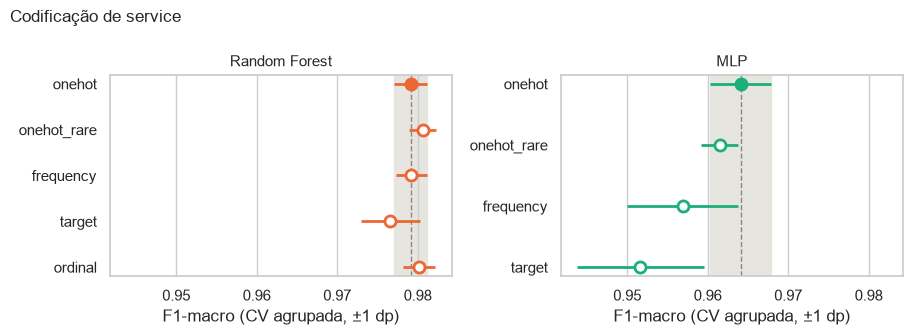

In [12]:
display(axis_table("codificacao"))
plot_axis("codificacao", "Codificação de service")

**O que se conclui.**
- **RF:** as cinco opções empatam dentro de 1 dp (0,9766 a 0,9806). Fica `onehot`, a referência.
  O `target` é o pior: concentrar a informação de 67 categorias em um número esconde
  combinações (`service` × `flag`) que as árvores aproveitam no one-hot.
- **MLP:** `onehot` é o melhor (0,9641). `frequency` (0,9569) e `target` (0,9516) perdem mais
  de 1 dp. Para a rede, uma só coluna numérica força uma relação monotônica entre a categoria e
  a saída, o que não existe: serviços com frequência parecida têm perfis de ataque opostos.
- O alerta do material sobre alta cardinalidade se confirma só em parte. A cauda é longa (50
  categorias com menos de 0,1% das linhas cada), mas essas colunas raras quase não pesam: agrupá-las
  (`onehot_rare`) não muda o resultado além do ruído. Com 70 mil linhas, as 67 colunas esparsas
  não atrapalham os modelos, e o one-hot preserva toda a informação sem ordem falsa.

## 6. Balanceamento de classes (requisito 2)

Apenas 5,8% das linhas são `anomaly` (16:1). O material da disciplina resume o dilema:
*oversampling* arrisca sobreajuste e instâncias irreais; *undersampling* arrisca perder
informação. Batista et al. (2004) recomendam SMOTE + Tomek quando há poucos positivos.
Comparamos sete técnicas contra não balancear:

| Técnica | O que faz (só no fold de treino) |
|---|---|
| `class_weight` | não reamostra: pesa os erros na classe rara (RF e HGB) |
| `ros` | replica `anomaly` até 10.000 linhas |
| `rus` | reduz `normal` a 10.000 linhas |
| `smote` | gera `anomaly` sintéticos por interpolação entre vizinhos, até 10.000 |
| `borderline_smote` | SMOTE só a partir dos positivos perto da fronteira |
| `smote_tomek` | SMOTE + remoção de pares de Tomek (limpa a fronteira) |
| `hybrid` | RUS de `normal` até 20.000 + SMOTE de `anomaly` até 5.000 |

O balanceador é o último passo antes do modelo, dentro do pipeline: só o `fit` reamostra, e as
linhas de validação nunca geram nem perdem instâncias. Por exigir dados completos, ele roda
depois da imputação; no HGB (NaN nativo), só `class_weight` é possível.

,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,HGB_native,none,0.9820,0.0015,0.0000,0.8816,0.9778,0.9531,0.284,True
1,HGB_native,class_weight,0.9805,0.0020,-0.0015,0.8808,0.9764,0.9487,0.708,False
2,RF,none,0.9791,0.0021,0.0000,0.8800,0.9703,0.9492,0.360,True
3,RF,class_weight,0.9738,0.0026,-0.0053,0.8760,0.9745,0.9257,0.618,False
4,RF,"ros, min_count=10000",0.9780,0.0014,-0.0011,0.8786,0.9774,0.9383,0.492,False
5,RF,"rus, max_count=10000",0.9716,0.0021,-0.0075,0.8753,0.9602,0.9306,0.650,False
6,RF,"smote, min_count=10000",0.9806,0.0012,0.0015,0.8809,0.9729,0.9526,0.412,False
7,RF,"borderline_smote, min_count=10000",0.9801,0.0012,0.0010,0.8803,0.9705,0.9526,0.420,False
8,RF,"smote_tomek, min_count=10000",0.9807,0.0012,0.0016,0.8809,0.9748,0.9510,0.414,False
9,RF,"hybrid, min_count=5000, max_count=20000",0.9758,0.0046,-0.0033,0.8788,0.9592,0.9477,0.524,False


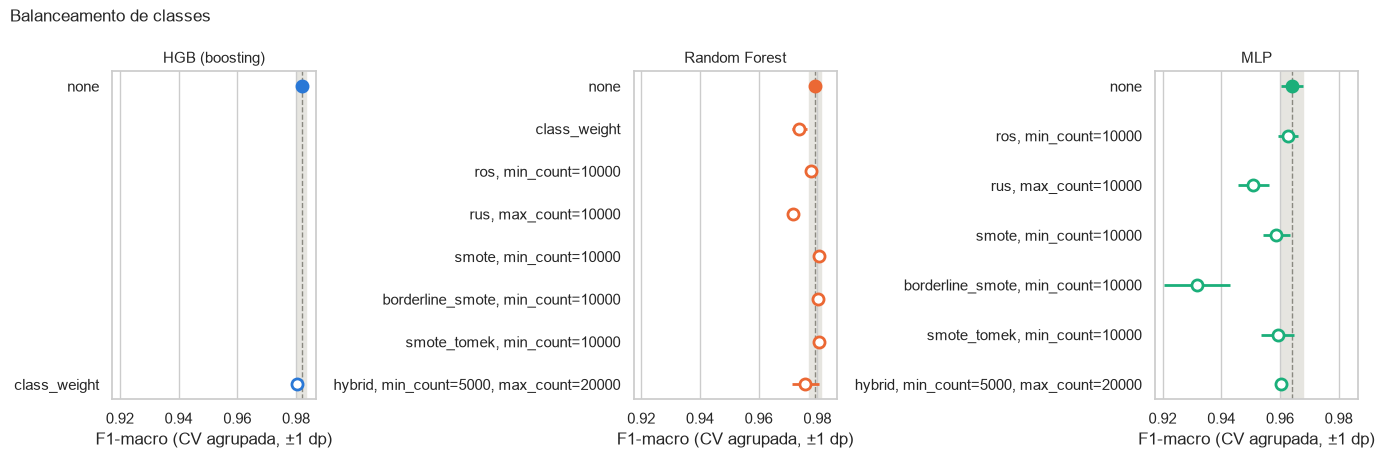

In [13]:
display(axis_table("balanceamento"))
plot_axis("balanceamento", "Balanceamento de classes")

**O que se conclui.**
- **Nenhuma técnica supera `none`** em nenhuma família. No RF, SMOTE e SMOTE + Tomek ficam na
  frente por pouco (0,9806 e 0,9807 contra 0,9791 ± 0,0021), dentro do ruído. Escolha: `none`.
- **RUS piora** em RF e MLP: descartar 80% dos `normal` perde informação sobre o tráfego legítimo,
  e os falsos positivos sobem. `class_weight` também piora no RF.
- **Por que balancear não ajuda aqui.** O F1-macro é calculado depois de escolher o limiar de
  decisão nas previsões OOF. Reamostrar muda a probabilidade que o modelo atribui a `anomaly`,
  mas o limiar ajustado já desloca a fronteira para o ponto que maximiza o F1-macro. A coluna
  `limiar` mostra isso: com ROS ou SMOTE o limiar sobe, compensando a probabilidade inflada.
  O balanceamento e o limiar resolvem o mesmo problema, e o limiar faz isso sem distorcer os
  dados de treino.
- **Limitação do SMOTE:** ele roda depois do one-hot e interpola as colunas binárias, gerando
  valores fracionários (meio `http`, meio `ftp`) que não existem em conexões reais. Isso
  explica parte do resultado fraco no MLP, sobretudo do `borderline_smote` (0,9318).

## 7. Normalização e transformação numérica (requisito 4)

Os volumes (`src_bytes`, `dst_bytes`, `duration`) e as contagens têm cauda muito longa. Para
modelos baseados em distância ou gradiente, como o MLP, a escala dos atributos importa.
Medimos a assimetria antes e depois do `log1p` (com sinal) nos atributos de cauda longa
(`config.HEAVY_TAILED`). É uma transformação fixa, por valor, sem parâmetros aprendidos:

In [14]:
heavy = X[config.HEAVY_TAILED]
skew = pd.DataFrame({"assimetria original": heavy.skew(),
                     "assimetria após log1p": signed_log1p(heavy).skew()}).round(1)
display(skew.sort_values("assimetria original", ascending=False).head(8))

,assimetria original,assimetria após log1p
dst_bytes,237.2,-0.5
num_root,187.5,21.7
duration,163.4,4.2
src_bytes,96.9,-1.4
num_file_creations,69.2,28.7
count,61.2,1.2
srv_count,57.6,1.3
num_compromised,55.1,9.0


Comparamos, no MLP:

| Opção | O que faz |
|---|---|
| `standard, log_transform=True` | `log1p` nos de cauda longa + padronização (média 0, dp 1) — referência |
| `standard, log_transform=False` | só padronização |
| `minmax, log_transform=True` | `log1p` + escala para [0, 1] |
| `robust, log_transform=True` | `log1p` + mediana e intervalo interquartil |
| `quantile, log_transform=False` | transforma cada atributo para distribuição normal por quantis |

As árvores (HGB, RF) dividem por limiares e são invariantes a transformações monotônicas:
padronizar ou aplicar `log1p` não muda nenhuma divisão possível. Por isso o eixo só é testado
no MLP; nas árvores, a escala fica em `none`.

,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,MLP,"standard, log_transform=True",0.9641,0.0038,0.0000,0.8696,0.9534,0.9102,0.428,True
1,MLP,"standard, log_transform=False",0.9551,0.0032,-0.0090,0.8629,0.9471,0.8831,0.480,False
2,MLP,"minmax, log_transform=True",0.9574,0.0065,-0.0067,0.8641,0.9611,0.8799,0.432,False
3,MLP,"robust, log_transform=True",0.9485,0.0077,-0.0156,0.8596,0.9323,0.8725,0.416,False
4,MLP,"quantile, log_transform=False",0.9584,0.0056,-0.0057,0.8655,0.9530,0.8901,0.464,False


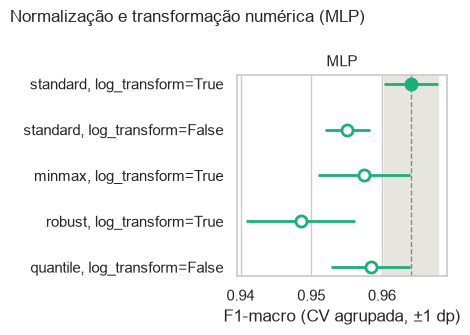

In [15]:
display(axis_table("escala"))
plot_axis("escala", "Normalização e transformação numérica (MLP)")

**O que se conclui.**
- `log1p` + padronização é a melhor opção (0,9641 ± 0,0038). Sem o `log1p` cai para 0,9551: com
  assimetria acima de 100, a padronização sozinha deixa quase todas as linhas espremidas perto
  de zero e poucas linhas em valores enormes, e a rede não consegue separar o tráfego comum.
- `minmax` (0,9574) sofre o mesmo efeito, porque o máximo é definido por poucas linhas extremas.
- `robust` é o pior (0,9485): em atributos com mais da metade dos valores iguais a zero, o
  intervalo interquartil é zero ou quase, e a escala explode.
- `quantile` (0,9584) resolve a cauda, mas achata as diferenças entre valores grandes, que são
  justamente as que separam alguns ataques de volume.

## 8. Redução de dimensionalidade (requisito 5)

Depois do one-hot, o RF e o MLP recebem cerca de 120 colunas, e a Etapa 1 mostrou grupos de
atributos muito correlacionados (as taxas `serror`/`rerror`). Comparamos:

| Técnica | O que faz |
|---|---|
| `none` | todas as colunas (referência) |
| `pca` | componentes principais que explicam 95% da variância |
| `kbest_f` | as 30 colunas com maior estatística F (ANOVA) em relação à classe |
| `kbest_mi` | as 30 colunas com maior informação mútua com a classe |
| `tree_select` | colunas com importância acima da mediana em um ExtraTrees ajustado no fold |

Optamos por redução de dimensionalidade, e não por seleção de instâncias (o enunciado aceita
qualquer uma das duas). A seleção de instâncias por limpeza de fronteira já aparece no eixo de
balanceamento (`smote_tomek`), e a de redundâncias, na Seção 2.

,familia,opcao,f1_macro,dp,ganho_vs_ref,f1_macro_bruto,precision_anomaly,recall_anomaly,limiar,escolhida
0,RF,none,0.9791,0.0021,0.0000,0.8800,0.9703,0.9492,0.360,False
1,RF,pca,0.6913,0.1187,-0.2878,0.6669,0.5230,0.3930,0.374,False
2,RF,"kbest_f, reduction_k=30",0.9585,0.0046,-0.0206,0.8645,0.9612,0.8816,0.456,False
3,RF,"kbest_mi, reduction_k=30",0.9748,0.0059,-0.0043,0.8776,0.9572,0.9461,0.330,False
4,RF,tree_select,0.9813,0.0020,0.0022,0.8813,0.9708,0.9570,0.352,True
5,MLP,none,0.9641,0.0038,0.0000,0.8696,0.9534,0.9102,0.428,True
6,MLP,pca,0.9509,0.0050,-0.0132,0.8622,0.9285,0.8855,0.446,False
7,MLP,"kbest_f, reduction_k=30",0.9498,0.0116,-0.0143,0.8591,0.9550,0.8575,0.468,False
8,MLP,"kbest_mi, reduction_k=30",0.9531,0.0054,-0.0110,0.8610,0.9427,0.8803,0.456,False
9,MLP,tree_select,0.9648,0.0025,0.0007,0.8720,0.9427,0.9222,0.434,False


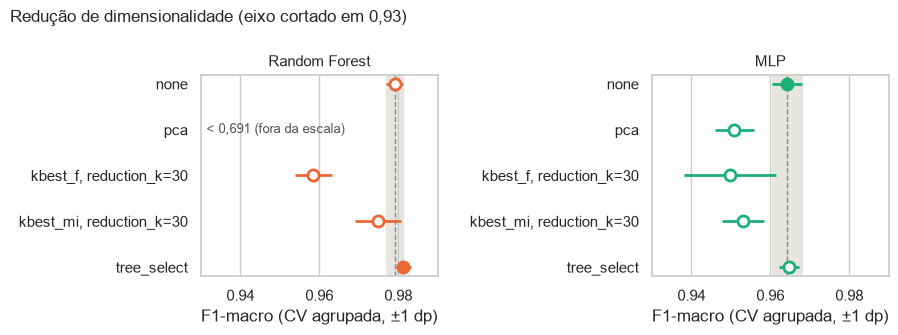

In [16]:
display(axis_table("reducao"))
plot_axis("reducao", "Redução de dimensionalidade (eixo cortado em 0,93)", xlim=(0.93, 0.99))

**O PCA no RF (0,69) é um artefato da comparação, não da técnica.** O RF usa `scaling="none"`, e
o PCA sem padronização é dominado pelos atributos de maior variância: `src_bytes` e `dst_bytes`,
na casa dos milhões, ocupam os primeiros componentes, e as taxas (entre 0 e 1) praticamente
somem. Para uma comparação justa, rodamos o PCA no RF com os dados padronizados e com `log1p`,
como no MLP:

In [17]:
rf_before_reduction = {k: v for k, v in best["RF"].items() if k != "reduction"}
fair = {}
for option in [{"reduction": "none"}, {"reduction": "pca"}]:
    params = {**rf_before_reduction, "scaling": "standard", "log_transform": True, **option}
    r = log.run("etapa2_reducao_pca_justo", "RF", make_model("RF", threads("RF")), X, y, groups,
                params, n_jobs=FOLD_JOBS)
    fair[describe(option)] = {"f1_macro": r["f1_macro_mean"], "dp": r["f1_macro_std"],
                              "f1_macro_bruto": r["f1_macro_noisy_mean"]}
display(pd.DataFrame(fair).T.rename_axis("RF com standard + log1p"))

,f1_macro,dp,f1_macro_bruto
RF com standard + log1p,,,
none,0.9800,0.0017,0.8804
pca,0.9593,0.0025,0.8673


**O que se conclui.**
- Com os dados padronizados, o PCA no RF deixa de ser um desastre, mas ainda perde para não
  reduzir (ver tabela acima). No MLP também perde (0,9509 contra 0,9641). O PCA combina os
  atributos em direções de **maior variância**, que não são necessariamente as que separam as
  classes, e o RF perde a capacidade de dividir por um atributo original de cada vez.
- `kbest_f` e `kbest_mi` com 30 colunas perdem nas duas famílias: o critério univariado descarta
  colunas que só ajudam em combinação com outras (por exemplo, categorias de `service` que
  importam só com certas `flag`).
- **`tree_select` é a única que ajuda:** no RF, 0,9813 ± 0,0020 contra 0,9791 ± 0,0021 (ganho de
  0,0022, logo acima de 1 dp). No MLP, empata (0,9648 contra 0,9641). A seleção por árvores
  avalia as colunas em conjunto e mantém só as de importância acima da mediana; as descartadas
  (como as dummies de `service` raras) quase não são usadas pelas árvores.
- Escolha: `tree_select` no RF; `none` no MLP. Uma vantagem extra para a Etapa 4: a seleção
  mantém os **atributos originais**, o que preserva a explicabilidade, ao contrário do PCA.
- O ganho do `tree_select` no RF passa da regra por pouco. A Seção 9 confere se ele se sustenta
  com mais repetições.

## 9. Robustez das escolhas (CV repetida 3×5)

A busca por coordenadas faz muitas comparações, e algumas escolhas passaram da regra por pouco.
Para conferir se as duas mudanças adotadas são reais, repetimos a CV 3 vezes (3 × 5 = 15 folds,
com sementes diferentes) comparando a configuração de partida com a escolhida. O MLP não entra:
a busca manteve a configuração de partida em todos os eixos.

In [18]:
robust_rows = []
for family in ["HGB_native", "RF"]:
    for label, params in [("partida", FAMILIES[family]), ("escolhida", best[family])]:
        r = log.run("etapa2_robustez", family, make_model(family, threads(family)), X, y, groups,
                    params, n_repeats=3, n_jobs=FOLD_JOBS)
        robust_rows.append({"familia": family, "configuracao": label,
                            "f1_macro": r["f1_macro_mean"], "dp": r["f1_macro_std"],
                            "f1_macro_bruto": r["f1_macro_noisy_mean"],
                            "segundos": r["cv_seconds"]})
robust = pd.DataFrame(robust_rows)
robust["ganho"] = (robust["f1_macro"] - robust.groupby("familia")["f1_macro"].transform("first")).round(4)
display(robust)

,familia,configuracao,f1_macro,dp,f1_macro_bruto,segundos,ganho
0,HGB_native,partida,0.9741,0.0033,0.8771,43.4,0.0000
1,HGB_native,escolhida,0.9824,0.0022,0.8816,45.9,0.0083
2,RF,partida,0.9798,0.0031,0.8806,121.5,0.0000
3,RF,escolhida,0.9806,0.0028,0.8808,172.9,0.0008


**O que se conclui.**
- **HGB, limpeza de rótulos: confirmada.** Com 15 folds, `majority_label` fica em 0,9824 ± 0,0022
  contra 0,9741 ± 0,0033 da partida, ganho de 0,0083, mais de 2 dp. É a mudança de
  pré-processamento com efeito real nesta base.
- **RF, `tree_select`: não confirmada.** O ganho cai para 0,0008 (0,9806 contra 0,9798, dp 0,0031),
  bem abaixo de 1 dp. O ganho de 0,0022 da busca era, em boa parte, variação de amostragem dos
  5 folds, o risco previsível de fazer muitas comparações seguidas.
- **Decisão para o RF:** manter `tree_select`, mas pelo motivo certo. O desempenho é equivalente
  ao de não reduzir, com metade das colunas e só atributos originais, o que barateia o treino e
  facilita a explicabilidade da Etapa 4. No relatório, ele aparece como "equivalente", não como
  "melhor".

## 10. Tabela comparativa consolidada e configurações escolhidas

A tabela completa (71 configurações + experimentos extras) está em `results/experiments.csv` e,
por eixo, em `results/etapa2_resultados_por_eixo.csv`. Abaixo, a melhor opção de cada eixo por
família, com o ganho sobre a referência do eixo:

In [19]:
summary = results.loc[results["escolhida"], ["familia", "eixo", "opcao", "f1_macro", "dp"]]
alternatives = (results.sort_values("f1_macro", ascending=False)
                .groupby(["familia", "eixo"], sort=False).head(1)
                .set_index(["familia", "eixo"])[["opcao", "f1_macro"]]
                .rename(columns={"opcao": "maior F1 do eixo", "f1_macro": "F1 maior"}))
summary = summary.join(alternatives, on=["familia", "eixo"]).reset_index(drop=True)
display(summary)

,familia,eixo,opcao,f1_macro,dp,maior F1 do eixo,F1 maior
0,HGB_native,redundancia,majority_label,0.9820,0.0015,majority_label,0.9820
1,HGB_native,dominio,nan,0.9820,0.0015,nan,0.9820
2,HGB_native,imputacao,none,0.9820,0.0015,none,0.9820
3,HGB_native,balanceamento,none,0.9820,0.0015,none,0.9820
4,RF,redundancia,none,0.9791,0.0021,relabel_model,0.9791
5,RF,imputacao,median,0.9791,0.0021,none,0.9801
6,RF,codificacao,onehot,0.9791,0.0021,onehot_rare,0.9806
7,RF,balanceamento,none,0.9791,0.0021,"smote_tomek, min_count=10000",0.9807
8,RF,reducao,tree_select,0.9813,0.0020,tree_select,0.9813
9,MLP,redundancia,none,0.9641,0.0038,drop_inconsistent,0.9657


Configuração final de pré-processamento de cada família. Ela segue para a Etapa 3, onde os
algoritmos e hiperparâmetros serão comparados. O arquivo `results/melhores_configuracoes.json`
guarda essas configurações (e, depois, os hiperparâmetros da Etapa 3).

In [20]:
best_file = config.RESULTS / "melhores_configuracoes.json"
stored = json.loads(best_file.read_text(encoding="utf-8")) if best_file.exists() else {}
stored.update(best)
best_file.write_text(json.dumps(stored, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.DataFrame(best).T.fillna("—"))

,redundancy,domain,imputation,scaling,log_transform,service_encoding,categorical_encoding,balancing,reduction
HGB_native,majority_label,nan,none,none,False,ordinal,ordinal,none,—
RF,none,nan,median,none,False,onehot,onehot,none,tree_select
MLP,none,nan,median,standard,True,onehot,—,none,none


In [21]:
final = results[results["escolhida"]].groupby("familia", sort=False).tail(1)[
    ["familia", "f1_macro", "dp", "f1_macro_bruto", "precision_anomaly", "recall_anomaly"]]
start = results.groupby("familia", sort=False).head(1)[["familia", "f1_macro"]]
final = final.merge(start.rename(columns={"f1_macro": "F1 da partida"}), on="familia")
final["ganho total"] = (final["f1_macro"] - final["F1 da partida"]).round(4)
display(final.set_index("familia"))

,f1_macro,dp,f1_macro_bruto,precision_anomaly,recall_anomaly,F1 da partida,ganho total
familia,,,,,,,
HGB_native,0.9820,0.0015,0.8816,0.9778,0.9531,0.9754,0.0066
RF,0.9813,0.0020,0.8813,0.9708,0.9570,0.9791,0.0022
MLP,0.9641,0.0038,0.8696,0.9534,0.9102,0.9641,0.0000


## 11. Conclusões e plano para a Etapa 3

| Requisito | Técnicas comparadas | Escolha | Justificativa |
|---|---|---|---|
| 1. Redundância/inconsistência | none, drop_duplicates, drop_inconsistent, majority_label, relabel_model | **majority_label** (HGB); none (RF, MLP) | o boosting memoriza rótulos trocados; o bagging dilui o ruído |
| Valores impossíveis | nan, none, clip | **nan** | o valor original é irrecuperável; saturar inventa um dado |
| Ausentes | NaN nativo, média, mediana, mediana + indicador, iterativa | **NaN nativo** (HGB); **mediana** (RF, MLP) | empates: vence a opção mais simples que o modelo aceita |
| 2. Balanceamento | class_weight, ROS, RUS, SMOTE, Borderline-SMOTE, SMOTE+Tomek, híbrido | **nenhum** | o limiar OOF já trata o desbalanceamento; RUS perde informação |
| 3. Codificação de `service` | one-hot, one-hot com raras, frequência, target, ordinal, nativa | **one-hot** (RF, MLP); nativa (HGB) | sem ordem falsa; 70 mil linhas sustentam 67 colunas |
| 4. Transformação numérica | standard, minmax, robust, quantile, com e sem log1p | **log1p + standard** (MLP); nenhuma (árvores) | caudas longas; árvores são invariantes a escala |
| 5. Redução | PCA, SelectKBest (F, MI), seleção por árvores | **tree_select** (RF); nenhuma (MLP, HGB) | equivalente a não reduzir (CV 3×5), com metade das colunas e atributos originais; o PCA perde informação discriminante |

**Lições para a Etapa 3.**
- O ganho real do pré-processamento veio da **limpeza de rótulos** no boosting. Os demais eixos
  pouco mudaram o resultado (e o único outro ganho, o `tree_select` no RF, não resistiu à CV
  repetida). O teto agora depende mais do algoritmo e dos hiperparâmetros do que do
  pré-processamento.
- As árvores (HGB 0,9824 e RF 0,9806 na CV 3×5) estão à frente do MLP (0,9641). Na Etapa 3, comparar ao
  menos HGB, XGBoost e RF com estas configurações, e incluir MLP, KNN e Naive Bayes como
  contraste, com ajuste de hiperparâmetros pelo mesmo protocolo de CV agrupada.
- Avaliar um ensemble (voto) das melhores árvores e congelar a configuração final em
  `results/final_config.json` antes de qualquer contato com o teste.

### Auditoria de vazamento deste notebook

`python -m nslkdd.audit notebooks/02_preprocessamento.ipynb` deve retornar **0 erros**. Nenhuma
célula carrega o teste, concatena bases, ajusta transformações fora do pipeline ou usa
`fit_resample` fora dele. O `DomainCleaner` da Seção 3 é usado só para contar valores
impossíveis: é uma regra fixa por linha, sem parâmetros aprendidos.